# Exporting the detector to ONNX and benchmarking runtimes

A detector that lives inside a robot rarely runs inside a Jupyter kernel. It is exported to an
interchange format and executed by an optimised runtime: **ONNX Runtime** on a PC or Jetson, TensorRT
on NVIDIA hardware, OpenVINO on Intel CPUs. This notebook exports the YOLO26n model we fine-tuned on
African wildlife (notebook 02) to **ONNX** and measures what the export buys.

In this notebook we:

1. export both heads to ONNX: the **NMS-free one-to-one** graph (output `(1, 300, 6)`, no
   post-processing needed) and the raw **one-to-many** graph (output `(1, 4 + C, 8400)`, NMS needed),
2. inspect the graphs (inputs/outputs, opset, operator mix),
3. check **numerical parity** between PyTorch and ONNX Runtime,
4. verify that ONNX Runtime's **CUDA execution provider** is really active on this Blackwell GPU,
5. benchmark PyTorch fp32/fp16 against ONNX Runtime CUDA (with and without I/O binding) and CPU,
6. re-validate the exported model to confirm that **mAP survives the export**.

**What you'll learn:** what an ONNX graph is, static vs dynamic shapes, execution providers,
host/device copies and I/O binding, and how to report deployment latency honestly.

**Prerequisites:** notebooks 01-02 and the fine-tuned checkpoint from
`scripts/train_yolo.py` (see the project README). TensorRT and `torch.compile` are covered in
project 14.

## Setup

`torch` is imported **before** `onnxruntime`: the `onnxruntime-gpu` 1.26 wheel (CUDA 12 build) finds
the CUDA/cuDNN libraries that the PyTorch wheels already loaded. Exported graphs go to
`outputs/03_object_detection/` (gitignored).

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# YOLO_AUTOINSTALL=false also stops the exporter from pip-installing an unpinned onnxruntime-gpu.
import os

os.environ["YOLO_AUTOINSTALL"] = "false"
import gc
import logging
import shutil
import sys
from collections import Counter
from copy import deepcopy

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import pynvml
import torch
from ultralytics import YOLO
from ultralytics.utils import LOGGER

# isort: split
import onnxruntime as ort  # imported after torch so the CUDA EP finds the CUDA/cuDNN libraries

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.metrics import box_iou

LOGGER.setLevel(logging.ERROR)
ort.set_default_logger_severity(3)  # errors only: keep ORT's per-node warnings out of the notebook
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "03_object_detection"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))
import detlib

summary = cvio.load_json(PROJ_DIR / "results" / "yolo26n_wildlife_summary.json")
CKPT = ROOT / summary["best_checkpoint"]
OUT = cvio.outputs_dir(PROJECT, create=True)
VAL = detlib.load_split(cvio.data_dir("ultralytics", "african-wildlife"), "val")
print(f"checkpoint: {CKPT.relative_to(ROOT)} ({'ok' if CKPT.exists() else 'MISSING'})")
print("onnx", onnx.__version__, "| onnxruntime", ort.__version__, "| available EPs:", ort.get_available_providers())

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
checkpoint: runs/03_object_detection/yolo26n_wildlife/weights/best.pt (ok)
onnx 1.23.2 | onnxruntime 1.26.0 | available EPs: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 1. Export both heads

`model.export(format="onnx")` traces the PyTorch graph with a dummy $1 \times 3 \times 640 \times 640$
input, writes ONNX (opset chosen automatically) and simplifies it with `onnxslim` (constant
folding, removing redundant reshapes). The `nms` argument selects what goes into the graph:

* `nms=False`: the one-to-one head plus its top-$k$ selection, so the output is the final
  `(1, 300, 6)` tensor `[x1, y1, x2, y2, score, class]` in letterboxed pixels;
* `nms=None` (default for most formats): the raw one-to-many head `(1, 4 + C, 8400)`, and the
  application has to run NMS itself;
* `nms=True` would embed an NMS operator for the one-to-many head (exercise 2).

The shapes are **static** (batch 1, 640x640), which lets runtimes pre-plan memory and pick kernels;
`dynamic=True` trades some of that for flexibility.

In [2]:
# --- Export the fine-tuned YOLO26n twice (one-to-one and one-to-many) and inspect the graphs ---
# The exporter writes best.onnx next to the checkpoint; we move each export to outputs/ under its own name.
onnx_paths = {}
for tag, nms_arg in [("one-to-one", False), ("one-to-many", None)]:
    f = YOLO(CKPT).export(format="onnx", imgsz=640, nms=nms_arg, simplify=True, device=0)
    dst = OUT / f"yolo26n_wildlife_{tag}.onnx"
    shutil.move(f, dst)
    onnx_paths[tag] = dst
rows = []
for tag, p in onnx_paths.items():
    g = onnx.load(p)
    ops = Counter(n.op_type for n in g.graph.node)
    rows.append({
        "graph": tag, "file": str(p.relative_to(ROOT)), "size [MB]": p.stat().st_size / 1e6,
        "opset": g.opset_import[0].version, "nodes": len(g.graph.node),
        "input": [d.dim_value for d in g.graph.input[0].type.tensor_type.shape.dim],
        "output": [d.dim_value for d in g.graph.output[0].type.tensor_type.shape.dim],
        "top ops": ", ".join(f"{k}:{v}" for k, v in ops.most_common(6)),
    })
graphs = pd.DataFrame(rows).set_index("graph")
graphs

,file,size [MB],opset,nodes,input,output,top ops
graph,,,,,,,
one-to-one,outputs/03_object_detection/yolo26n_wildlife_o...,9.867008,18,384,"[1, 3, 640, 640]","[1, 300, 6]","Conv:102, Mul:90, Sigmoid:88, Concat:24, Add:2..."
one-to-many,outputs/03_object_detection/yolo26n_wildlife_o...,9.855283,18,368,"[1, 3, 640, 640]","[1, 8, 8400]","Conv:102, Mul:90, Sigmoid:88, Concat:23, Add:2..."


## 2. ONNX Runtime sessions and the CUDA execution provider

An ONNX Runtime **session** partitions the graph across **execution providers (EPs)** in priority
order; nodes an EP cannot run fall back to the next one. If the CUDA EP fails to load (missing
libraries, unsupported GPU), ORT *silently* falls back to the CPU, so always check
`session.get_providers()`. We also watch this process's GPU memory through NVML, which sees
allocations that PyTorch's allocator does not (ORT has its own memory arena).

On this GPU, ONNX Runtime 1.26 logs a warning for every `Conv` node of the form
"running in Fallback mode. May be extremely slow" when the CUDA session is created. The message
says that its cuDNN engine selection did not return a preferred engine for these convolutions on
sm_120 and a fallback engine is used instead. We set ORT's log level to errors only to keep the
notebook readable, and let the latency measurements below show what this costs.

In [3]:
# --- Create CUDA and CPU sessions for the one-to-one graph and confirm the CUDA EP is active ---
# NVML reports this process's total GPU memory, including ORT's arena and the shared CUDA context.
pynvml.nvmlInit()
NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)


def process_gpu_mib():
    for p in pynvml.nvmlDeviceGetComputeRunningProcesses(NVML_HANDLE):
        if p.pid == os.getpid() and p.usedGpuMemory is not None:
            return p.usedGpuMemory / 2**20
    return float("nan")


mem_before_ort = process_gpu_mib()
sess_cuda = ort.InferenceSession(onnx_paths["one-to-one"], providers=[("CUDAExecutionProvider", {"device_id": 0}), "CPUExecutionProvider"])
sess_cpu = ort.InferenceSession(onnx_paths["one-to-one"], providers=["CPUExecutionProvider"])
print("CUDA session providers:", sess_cuda.get_providers())
print("CPU  session providers:", sess_cpu.get_providers())
assert sess_cuda.get_providers()[0] == "CUDAExecutionProvider", "CUDA EP not active - ORT fell back to the CPU"
inp, out = sess_cuda.get_inputs()[0], sess_cuda.get_outputs()[0]
print(f"input  {inp.name}: {inp.shape} {inp.type}\noutput {out.name}: {out.shape} {out.type}")

CUDA session providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
CPU  session providers: ['CPUExecutionProvider']
input  images: [1, 3, 640, 640] tensor(float)
output output0: [1, 300, 6] tensor(float)


## 3. Numerical parity

Export should not change the function the network computes, only how it is executed. We feed the
same letterboxed validation image to PyTorch (fused, fp32, one-to-one head), ORT-CUDA and ORT-CPU
and compare the outputs. Differences of order $10^{-4}$ come from different convolution algorithms and
summation orders; they must not change the detections.

One subtlety: the graph ends in a **top-300 selection** over 8400 cells. Most of those 300 rows have
near-identical, tiny scores, so a $10^{-6}$ change can swap their order, and an element-wise comparison
of the full `(1, 300, 6)` tensors would report huge "differences" between rows that are simply
permuted. We therefore compare (a) the **confident detections** (score > 0.25), matched by IoU, and
(b) the **sorted score vectors** of all 300 rows, which are order-independent.

In [4]:
# --- Compare PyTorch, ORT-CUDA and ORT-CPU outputs on one validation image ---
# letterbox_np reproduces the 640x640 square letterbox (grey padding) used at export time.
def letterbox_np(img, size=640):
    h, w = img.shape[:2]
    r = size / max(h, w)
    nh, nw = round(h * r), round(w * r)
    out = np.full((size, size, 3), 114, np.uint8)
    py, px = (size - nh) // 2, (size - nw) // 2
    out[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return out


sample = VAL[10]
# HWC uint8 -> NCHW float32 in [0, 1]. transpose() only changes strides and astype() keeps that
# memory layout, so ascontiguousarray is needed to get a real C-contiguous NCHW buffer (see section 4).
x_np = np.ascontiguousarray(letterbox_np(cvio.read_image(sample.image)).transpose(2, 0, 1)[None] / 255.0, dtype=np.float32)
x_gpu = torch.from_numpy(x_np).to(device)  # (1, 3, 640, 640) float32, contiguous
net = deepcopy(YOLO(CKPT).model).to(device).eval()
net.model[-1].end2end = True
net.fuse(verbose=False)
with torch.inference_mode():
    y_torch = net(x_gpu)[0].cpu().numpy()
y_cuda = sess_cuda.run(None, {inp.name: x_np})[0]
y_cpu = sess_cpu.run(None, {inp.name: x_np})[0]


def parity_row(name, y, ref, thr=0.25):
    # Match each confident reference detection to its best-IoU counterpart (rows may be permuted).
    t, o = ref[0][ref[0, :, 4] > thr], y[0][y[0, :, 4] > thr]
    iou = box_iou(t[:, :4], o[:, :4])
    j = iou.argmax(1)
    return {"runtime vs PyTorch": name, "detections (conf>0.25)": f"{len(o)} vs {len(t)}",
            "min matched IoU": iou.max(1).min(),
            "max |d box| [px]": np.abs(o[j, :4] - t[:, :4]).max(),
            "max |d score|": np.abs(o[j, 4] - t[:, 4]).max(),
            "same classes": bool((o[j, 5] == t[:, 5]).all()),
            "max |d sorted scores| (300 rows)": np.abs(np.sort(y[0, :, 4]) - np.sort(ref[0, :, 4])).max()}


parity = pd.DataFrame([parity_row(n, y, y_torch) for n, y in [("ORT CUDA", y_cuda), ("ORT CPU", y_cpu)]])
parity.set_index("runtime vs PyTorch")

,detections (conf>0.25),min matched IoU,max |d box| [px],max |d score|,same classes,max |d sorted scores| (300 rows)
runtime vs PyTorch,,,,,,
ORT CUDA,1 vs 1,0.999992,0.002380,0.000146,True,0.000146
ORT CPU,1 vs 1,0.999877,0.029175,0.000453,True,0.000453


## 4. Latency

Five ways to run the same one-to-one network at batch 1 on a 640x640 input:

| backend | input / output |
|---|---|
| PyTorch fp32 / fp16 (fused, eager) | tensors already on the GPU |
| ORT CUDA EP, NumPy I/O | host array in, host array out: includes the $\approx 4.9$ MB host-to-device copy |
| ORT CUDA EP, I/O binding | ORT reads/writes PyTorch GPU tensors directly (no copies) |
| ORT CPU EP | everything on the CPU |

**I/O binding** matters when the image is already on the GPU (e.g. decoded by NVDEC or produced by
a previous GPU stage). It hands ORT *raw device pointers*, which has two sharp edges:

* ORT assumes a dense, C-contiguous buffer of the declared shape. A PyTorch tensor made from
  `img.transpose(2, 0, 1)` is a strided **view** whose memory is still HWC; binding its
  `data_ptr()` makes ORT read the pixels in the wrong order and silently return garbage
  detections (no error is raised). This exact bug cost us a run while building this notebook, so
  the cell below asserts `is_contiguous()` and checks the bound output against the NumPy path.
* PyTorch and ORT launch work on different CUDA streams, so synchronise before ORT reads a tensor
  that PyTorch has just written.

As in notebook 01, all GPU backends are timed **interleaved over 5 rounds**
(median of per-round medians) because the laptop is shared with other jobs; the much slower CPU
EP gets fewer iterations. Memory: PyTorch peak allocated for the PyTorch rows, the NVML increase in
process GPU memory caused by creating and running the ORT session for the ORT rows (different
mechanisms, so compare within a column only roughly).

In [5]:
# --- Build the benchmark callables (PyTorch fp32/fp16, ORT CUDA numpy / I/O binding, ORT CPU) ---
# I/O binding points ORT at the PyTorch input tensor and a preallocated output tensor on the GPU.
torch_mem = {}
nets = {}
for prec in ("fp32", "fp16"):
    gc.collect()
    torch.cuda.empty_cache()
    base = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    n = deepcopy(net).half() if prec == "fp16" else net
    xg = x_gpu.half() if prec == "fp16" else x_gpu
    with torch.inference_mode():
        n(xg)
    torch.cuda.synchronize()
    torch_mem[prec] = (torch.cuda.max_memory_allocated() - base) / 2**20
    nets[prec] = (n, xg)

assert x_gpu.is_contiguous(), "I/O binding needs a contiguous NCHW tensor"
y_bind = torch.empty(tuple(y_cuda.shape), device=device, dtype=torch.float32)
binding = sess_cuda.io_binding()
binding.bind_input(inp.name, "cuda", 0, np.float32, list(x_gpu.shape), x_gpu.data_ptr())
binding.bind_output(out.name, "cuda", 0, np.float32, list(y_bind.shape), y_bind.data_ptr())
torch.cuda.synchronize()  # x_gpu was written on PyTorch's stream; ORT runs on its own stream
sess_cuda.run_with_iobinding(binding)
bind_check = parity_row("ORT CUDA I/O binding vs NumPy I/O", y_bind.cpu().numpy(), y_cuda)
assert bind_check["min matched IoU"] > 0.999 and bind_check["same classes"], bind_check
ort_cuda_mib = process_gpu_mib() - mem_before_ort


def torch_fn(prec):
    n, xg = nets[prec]
    with torch.inference_mode():
        return n(xg)


backends = {
    "PyTorch fp32": lambda: torch_fn("fp32"),
    "PyTorch fp16": lambda: torch_fn("fp16"),
    "ORT CUDA fp32 (NumPy I/O)": lambda: sess_cuda.run(None, {inp.name: x_np}),
    "ORT CUDA fp32 (I/O binding)": lambda: sess_cuda.run_with_iobinding(binding),
}
print(f"PyTorch peak allocated: {torch_mem}; ORT CUDA session NVML increase: {ort_cuda_mib:.0f} MiB")

PyTorch peak allocated: {'fp32': 19.75, 'fp16': 17.0615234375}; ORT CUDA session NVML increase: 144 MiB


Run the interleaved timing (round 0 is a discarded warm-up), then the CPU EP once with fewer
iterations.

In [6]:
# --- Interleaved GPU timing over 5 rounds + CPU EP ---
# p50 per round; the table reports the median and the min/max across rounds.
ROUNDS = 5
t = {k: [] for k in backends}
for rnd in range(-1, ROUNDS):
    for k, fn in backends.items():
        r = benchmark(fn, warmup=10, iters=100)
        if rnd >= 0:
            t[k].append(r["p50_ms"])
cpu = benchmark(lambda: sess_cpu.run(None, {inp.name: x_np}), warmup=3, iters=20, cuda=False)
rows = [{"backend": k, "latency [ms]": np.median(v), "min [ms]": np.min(v), "max [ms]": np.max(v)} for k, v in t.items()]
rows.append({"backend": "ORT CPU fp32", "latency [ms]": cpu["p50_ms"], "min [ms]": cpu["min_ms"], "max [ms]": cpu["p90_ms"]})
bench_df = pd.DataFrame(rows).set_index("backend")
bench_df["FPS"] = 1000 / bench_df["latency [ms]"]
bench_df["GPU memory [MiB]"] = [torch_mem["fp32"], torch_mem["fp16"], ort_cuda_mib, ort_cuda_mib, 0.0]
bench_df["memory metric"] = ["torch peak allocated"] * 2 + ["NVML process increase"] * 2 + ["(CPU)"]
bench_df.round(2)

,latency [ms],min [ms],max [ms],FPS,GPU memory [MiB],memory metric
backend,,,,,,
PyTorch fp32,2.83,2.71,3.05,353.48,19.75,torch peak allocated
PyTorch fp16,2.57,2.57,2.57,389.22,17.06,torch peak allocated
ORT CUDA fp32 (NumPy I/O),3.52,3.42,3.66,284.11,144.00,NVML process increase
ORT CUDA fp32 (I/O binding),3.35,3.28,3.46,298.45,144.00,NVML process increase
ORT CPU fp32,15.89,14.22,17.52,62.94,0.00,(CPU)


## 5. Does accuracy survive the export?

Latency is worthless if the exported model is worse. Ultralytics can validate an `.onnx` file
directly (it runs it with ONNX Runtime, batch 1). We compare against the PyTorch checkpoint
validated with the same one-to-one head.

There is a trap in this comparison. For `.pt` models, `YOLO.val()` defaults to **rectangular
batches** (`rect=True`): every batch is letterboxed to the smallest stride-32 shape that fits its
images (e.g. 640x480 for 4:3 photos), so there is less grey padding. A static 1x3x640x640 ONNX
graph can only take **square** inputs, so the validator switches to `rect=False` for it. To
separate "the export changed the model" from "the preprocessing changed", we also validate the
PyTorch checkpoint with `rect=False`. The `inference [ms/img]` column is Ultralytics' own timer
and is not comparable across rows (batch 16 vs batch 1); use section 4 for latency.

In [7]:
# --- Validate PyTorch (one-to-one head, rect and square letterbox) and the ONNX graph on val ---
# The ONNX model is static batch-1 / 640x640, so Ultralytics validates it image by image (rect=False).
val_rows = []
for name, weights, kw in [("PyTorch .pt, rect batches", CKPT, {"nms": False, "batch": 16}),
                          ("PyTorch .pt, square 640", CKPT, {"nms": False, "batch": 16, "rect": False}),
                          ("ONNX Runtime, square 640", onnx_paths["one-to-one"], {"batch": 1})]:
    m = YOLO(weights, task="detect").val(data="african-wildlife.yaml", split="val", imgsz=640, plots=False,
                                         project=str(cvio.runs_dir(PROJECT)), name="val_onnx", exist_ok=True,
                                         verbose=False, **kw)
    val_rows.append({"model": name, "mAP50": m.box.map50, "mAP50-95": m.box.map,
                     "inference [ms/img]": m.speed["inference"]})
val_df = pd.DataFrame(val_rows).set_index("model")
val_df.round(4)

,mAP50,mAP50-95,inference [ms/img]
model,,,
"PyTorch .pt, rect batches",0.9549,0.8068,1.8923
"PyTorch .pt, square 640",0.9473,0.8004,2.1717
"ONNX Runtime, square 640",0.9472,0.8000,3.1651


## Results

Batch-1 latency of the fine-tuned YOLO26n (one-to-one head, 640x640) per backend on the RTX 5060
Laptop GPU (CPU EP on the Intel Core Ultra 9 275HX), plus the accuracy check.

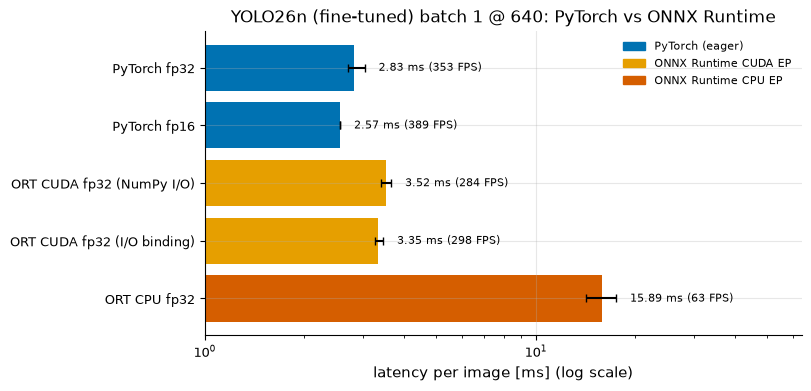

In [8]:
# --- Results figure: latency per backend (log scale) ---
# Error bars show the min-max of the per-round medians (CPU EP: min to p90 of its single run).
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
b = bench_df
err = [b["latency [ms]"] - b["min [ms]"], b["max [ms]"] - b["latency [ms]"]]
family = {"PyTorch (eager)": viz.color(0, unit=True), "ONNX Runtime CUDA EP": viz.color(1, unit=True),
          "ONNX Runtime CPU EP": viz.color(5, unit=True)}
colors = [family[k] for k in ["PyTorch (eager)"] * 2 + ["ONNX Runtime CUDA EP"] * 2 + ["ONNX Runtime CPU EP"]]
ax.barh(b.index, b["latency [ms]"], xerr=err, capsize=3, color=colors)
for i, (v, hi) in enumerate(zip(b["latency [ms]"], b["max [ms]"])):
    ax.text(hi * 1.1, i, f"{v:.2f} ms ({1000 / v:.0f} FPS)", va="center", fontsize=8)  # right of the error bar
ax.legend(handles=[Patch(color=c, label=k) for k, c in family.items()], loc="upper right", fontsize=8)
ax.set_xscale("log"), ax.set_xlabel("latency per image [ms] (log scale)")
ax.set_title("YOLO26n (fine-tuned) batch 1 @ 640: PyTorch vs ONNX Runtime"), ax.invert_yaxis()
ax.set_xlim(1, b["latency [ms]"].max() * 4)
viz.savefig(fig, PROJECT, "onnx_latency")
plt.show()

Summary table (latency, memory, export size and accuracy):

In [9]:
# --- Summary table ---
# One row per backend; mAP is attached to the PyTorch fp32 and ORT rows it was measured for.
res = bench_df[["latency [ms]", "FPS", "GPU memory [MiB]", "memory metric"]].copy()
# Both mAP values use square 640 letterboxing, i.e. the same preprocessing (section 5).
res["mAP50-95 (val, square 640)"] = [val_df.loc["PyTorch .pt, square 640", "mAP50-95"], np.nan,
                                     val_df.loc["ONNX Runtime, square 640", "mAP50-95"],
                                     val_df.loc["ONNX Runtime, square 640", "mAP50-95"], np.nan]
res["model file [MB]"] = [CKPT.stat().st_size / 1e6] * 2 + [graphs.loc["one-to-one", "size [MB]"]] * 3
res.round({"latency [ms]": 2, "FPS": 1, "GPU memory [MiB]": 1, "mAP50-95 (val, square 640)": 4, "model file [MB]": 2})

,latency [ms],FPS,GPU memory [MiB],memory metric,"mAP50-95 (val, square 640)",model file [MB]
backend,,,,,,
PyTorch fp32,2.83,353.5,19.8,torch peak allocated,0.8004,5.44
PyTorch fp16,2.57,389.2,17.1,torch peak allocated,NaN,5.44
ORT CUDA fp32 (NumPy I/O),3.52,284.1,144.0,NVML process increase,0.8000,9.87
ORT CUDA fp32 (I/O binding),3.35,298.4,144.0,NVML process increase,0.8000,9.87
ORT CPU fp32,15.89,62.9,0.0,(CPU),NaN,9.87


### Takeaways

* **The export is faithful.** On the parity image ORT-CUDA reproduces PyTorch's boxes to within
  0.002 px and its scores to within 1.5e-4 (ORT-CPU: 0.03 px and 4.5e-4), with identical classes.
  Over the whole val split the ONNX graph scores mAP50-95 0.8000 versus 0.8004 for the PyTorch
  checkpoint run with the same square 640 letterbox (mAP50 0.9472 vs 0.9473).
* **Preprocessing moved mAP more than the export did.** With Ultralytics' default rectangular
  batches the same PyTorch model scores 0.8068 mAP50-95 (0.9549 mAP50). Comparing that number with
  the ONNX result would wrongly blame the export for a 0.007 drop that actually comes from the extra
  letterbox padding. Compare runtimes with identical preprocessing.
* **The one-to-one head makes the graph self-contained.** The NMS-free export ends in a fixed
  `(1, 300, 6)` tensor, so the application only thresholds scores; the one-to-many export
  (`(1, 8, 8400)` here: 4 box values + 4 classes) needs an NMS implementation in every
  language/runtime that consumes it.
* **ONNX Runtime's CUDA EP runs on Blackwell (sm_120) with the CUDA 12 build of onnxruntime-gpu
  1.26, but it was not faster than eager PyTorch at batch 1 here:** 3.35 ms with I/O binding and
  3.52 ms with NumPy I/O, versus 2.83 ms (fp32) and 2.57 ms (fp16) for the fused PyTorch model. A
  plausible contributor is the cuDNN "Fallback mode" warning that ORT prints for every `Conv` on
  this GPU (it does not get its preferred convolution engines on the new architecture); we did not
  isolate the cause. I/O binding saved 0.17 ms per frame by skipping the 4.9 MB host-to-device copy
  and the copy back.
* **The CPU EP is about 5.6x slower (15.9 ms, 63 FPS) but still real-time for this small model**,
  a usable fallback for robots without a discrete GPU. It is the noisiest row (14.2 ms min, 17.5 ms
  p90) because other processes share the CPU.
* **Memory is not a constraint:** under 20 MiB of PyTorch allocations per forward pass and 144 MiB of
  extra process GPU memory for the whole ORT CUDA session (arena plus cuDNN workspace).
* **These are batch-1 numbers on a shared laptop**; for maximum throughput use TensorRT fp16/int8 and
  batching (exercise 1 and project 14).

## Exercises

Solutions are in `projects/03_object_detection/solutions/`.

**Exercise 1 - dynamic batch.** Export the one-to-one graph with `dynamic=True` and measure ORT-CUDA
throughput (images/s) for batch sizes 1, 2, 4 and 8. Where does batching stop helping?

In [10]:
# --- Exercise 1: dynamic-batch export and throughput ---
# TODO: YOLO(CKPT).export(format="onnx", dynamic=True, nms=False, ...), create a CUDA session and
#       benchmark sess.run on random (B, 3, 640, 640) inputs; plot images/s vs B.

**Exercise 2 - NMS inside the graph.** Export the one-to-many head with `nms=True` so the NMS runs
inside ONNX Runtime. Compare its outputs (after a 0.25 threshold) and its latency with the
one-to-one graph.

In [11]:
# --- Exercise 2: embedded NMS ---
# TODO: export with nms=True, inspect the output shape, run both graphs on x_np, match the boxes
#       with box_iou and benchmark both sessions.

**Exercise 3 - input resolution.** Export at `imgsz=320` and `imgsz=480`, then measure ORT-CUDA
latency and val mAP50-95 (`YOLO(path, task="detect").val(..., imgsz=<same size>)`). Plot the
accuracy/latency trade-off.

In [12]:
# --- Exercise 3: resolution trade-off ---
# TODO: loop over imgsz in (320, 480, 640): export, benchmark one CUDA session, validate, plot.